# code_132 · Off-grid residuals, missing boundaries and difficult frequencies

**Book:** section 25.6. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_132).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2932;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2932


<a id="failure-audit-contract"></a>
 ## Small source residual can leave the solution wrong
 On[0,1], solve −u''=(m*pi)² sin(m*pi*x) with zero endpoints. Compare m=1 and m=8, using a two-layer sixteen-unit tanh model,32 interior source positions and1,200 Adam updates at0.005. The physics-only recipe minimizes residual normalized by(m*pi)² plus ten times endpoint MSE; the data-only recipe instead observes exact displacement at those same32 positions and uses the same endpoint penalty. These are different evidence budgets and neither is selected using final truth. A separate63-point development residual diagnostic and401-point field/residual assessment are reported. Before fitting, an explicit oscillatory witness passes a different collocation grid yet fails between its points. An omitted-boundary affine family has identical equation residual and different solutions.


,model,frequency,recipe,source_residual_MSE,development_residual_MSE,final_residual_MSE,final_field_MSE,max_boundary_defect,parameters
0,"Physics only, m=1",1,Physics only,0.000015,0.000023,0.000025,1.558778e-08,0.000006,321
1,"Data only, m=1",1,Data only,0.002345,0.002764,0.002798,3.620266e-06,0.000088,321
2,"Physics only, m=8",8,Physics only,0.515615,0.499990,0.498743,4.987890e-01,0.000010,321
3,"Data only, m=8",8,Data only,0.515618,0.499993,0.498746,4.975690e-01,0.007667,321


Numerical references: [{'frequency': 1, 'final_nodes': 473, 'max_field_error': 3.841771345491907e-11, 'max_relative_residual': 9.998324025661542e-09}, {'frequency': 8, 'final_nodes': 4513, 'max_field_error': 1.840105845474227e-11, 'max_relative_residual': 9.962492709752112e-09}]


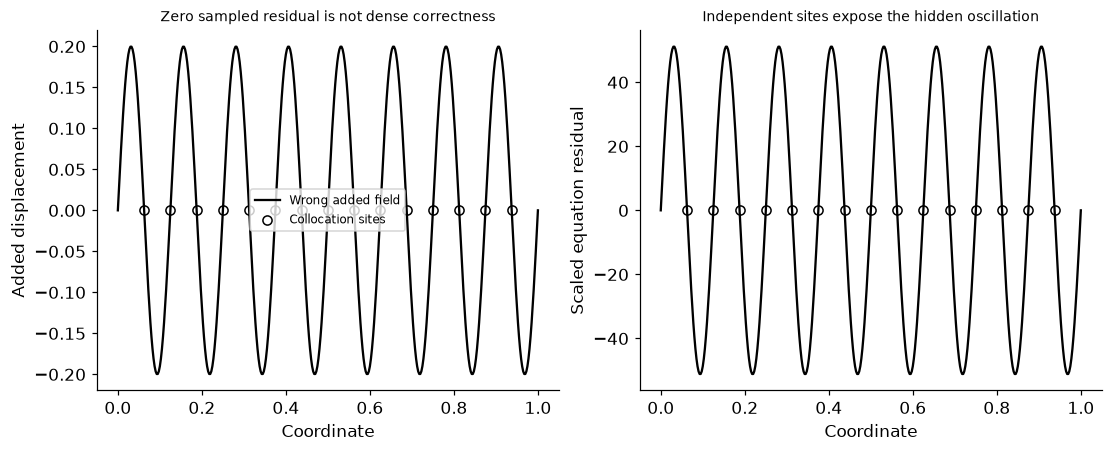

In [2]:
from scipy.integrate import solve_bvp
def derivative(y,x,order=1):
    for j in range(order):y=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    return y
witness_x=np.arange(1,16)/16;dense=np.linspace(0,1,401);amplitude=.2;source_residual=amplitude*16**2*np.sin(16*np.pi*witness_x);dense_residual=amplitude*16**2*np.sin(16*np.pi*dense);witness_error=amplitude*np.sin(16*np.pi*dense);assert np.mean(source_residual**2)<1e-20 and np.mean(dense_residual**2)>100
# u and u + 0.3*x + 0.2 have identical second derivative; missing endpoint constraints do not identify a unique field.
missing_boundary_endpoint=np.array([.2,.5]);assert np.max(np.abs(missing_boundary_endpoint))==.5
xs=torch.tensor(np.arange(1,33)/33)[:,None].requires_grad_(True);xb=torch.tensor([[0.],[1.]]);xd=torch.tensor((np.arange(63)+.5)/63)[:,None].requires_grad_(True);xt=torch.tensor(dense)[:,None].requires_grad_(True);models={};rows=[];histories={};references=[]
for frequency in [1,8]:
    omega=frequency*np.pi;truth_source=torch.sin(omega*xs).detach()
    for recipe in ['Physics only','Data only']:
        torch.manual_seed(SEED);model=nn.Sequential(nn.Linear(1,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,1));opt=torch.optim.Adam(model.parameters(),lr=.005);history=[]
        for step in range(1,1201):
            opt.zero_grad();p=model(xs);residual=-derivative(p,xs,2)/omega**2-torch.sin(omega*xs);term=residual.square().mean() if recipe=='Physics only' else (p-truth_source).square().mean();bc=model(xb).square().mean();loss=term+10*bc;loss.backward();opt.step()
            if step%40==0:history.append([step,float(term.detach()),float(bc.detach())])
        p=model(xt);residual=-derivative(p,xt,2)/omega**2-torch.sin(omega*xt);dp=model(xd);dev_residual=-derivative(dp,xd,2)/omega**2-torch.sin(omega*xd);source_p=model(xs);source_r=-derivative(source_p,xs,2)/omega**2-torch.sin(omega*xs);name=f'{recipe}, m={frequency}';models[name]=model;histories[name]=history;rows.append({'model':name,'frequency':frequency,'recipe':recipe,'source_residual_MSE':float(source_r.square().mean().detach()),'development_residual_MSE':float(dev_residual.square().mean().detach()),'final_residual_MSE':float(residual.square().mean().detach()),'final_field_MSE':float((p-torch.sin(omega*xt)).square().mean().detach()),'max_boundary_defect':float(model(xb).abs().max().detach()),'parameters':sum(p.numel() for p in model.parameters())})
    mesh=np.linspace(0,1,17);ref=solve_bvp(lambda x,y:np.vstack([y[1],-omega**2*np.sin(omega*x)]),lambda a,b:np.array([a[0],b[0]]),mesh,np.zeros((2,len(mesh))),tol=1e-8,max_nodes=5000);assert ref.success
    references.append({'frequency':frequency,'final_nodes':len(ref.x),'max_field_error':float(np.max(np.abs(ref.sol(dense)[0]-np.sin(omega*dense)))),'max_relative_residual':float(ref.rms_residuals.max())})
RESULTS.update(comparisons=rows,reference_solvers=references,collocation_witness={'source_points':15,'source_scaled_residual_MSE':float(np.mean(source_residual**2)),'dense_scaled_residual_MSE':float(np.mean(dense_residual**2)),'dense_field_MSE':float(np.mean(witness_error**2)),'max_boundary_defect':0.},missing_boundary_affine_endpoint_defects=missing_boundary_endpoint.tolist(),source_points_per_fit=32,development_points=63,final_points=401,updates_per_recipe=1200,learning_rate=.005);display(pd.DataFrame(rows));print('Numerical references:',references)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(dense,witness_error,color='black',label='Wrong added field');axes[0].scatter(witness_x,amplitude*np.sin(16*np.pi*witness_x),facecolors='white',edgecolors='black',label='Collocation sites');axes[0].set(xlabel='Coordinate',ylabel='Added displacement',title='Zero sampled residual is not dense correctness');axes[0].legend(fontsize=8);axes[1].plot(dense,dense_residual,color='black');axes[1].scatter(witness_x,source_residual,facecolors='white',edgecolors='black');axes[1].set(xlabel='Coordinate',ylabel='Scaled equation residual',title='Independent sites expose the hidden oscillation');plt.show()


<a id="frequency-and-reference"></a>
 ## Retain a failed fit and diagnose its claim
 The oscillatory witness is an analytic counterexample, not a trained model or a universal error bound. Its endpoints are correct and its sampled residual is almost zero, yet the added field is nonzero between samples. The trained low/high-frequency comparisons are separate finite-budget experiments. A smooth tanh network can represent oscillations, but this particular optimization/width/budget can fail at higher frequency. That result alone does not identify one universal cause. Residual normalization changes gradient scales; source locations, boundary defects, model approximation and optimizer progress all matter. Dense reference displacement is used only for assessment. The native boundary-value solver must report success and is checked against analytic truth, so solver error is not silently treated as physical truth. A missing endpoint condition can leave an affine ambiguity even if the differential equation holds everywhere.


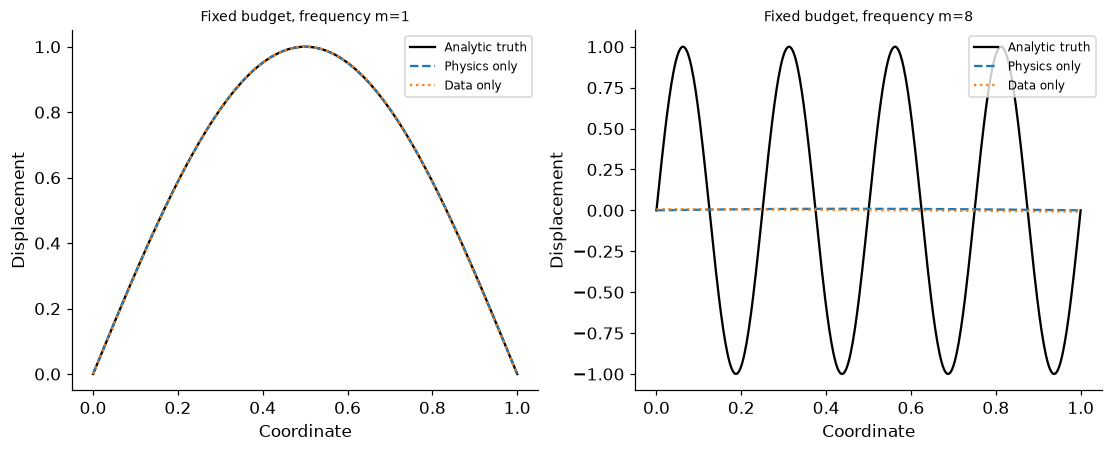

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for panel,frequency in enumerate([1,8]):
    axes[panel].plot(dense,np.sin(frequency*np.pi*dense),'k-',label='Analytic truth')
    for recipe,style in [('Physics only','--'),('Data only',':')]:axes[panel].plot(dense,models[f'{recipe}, m={frequency}'](xt).detach().numpy().ravel(),style,label=recipe)
    axes[panel].set(xlabel='Coordinate',ylabel='Displacement',title=f'Fixed budget, frequency m={frequency}');axes[panel].legend(fontsize=8)
plt.show()
assert len(rows)==4 and all(np.isfinite(r['final_field_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_132','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual low and high frequency PINN fits', 'matched-budget data-only references', 'off-collocation adversarial witness', 'missing-boundary nonuniqueness', 'native refined numerical reference'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual low and high frequency PINN fits", "matched-budget data-only references", "off-collocation adversarial witness", "missing-boundary nonuniqueness", "native refined numerical reference"], "elapsed_seconds": 2.511, "example_id": "code_132", "hardware": "Darwin arm64 CPU", "results": {"collocation_witness": {"dense_field_MSE": 0.0199501246882793, "dense_scaled_residual_MSE": 1307.4513715710723, "max_boundary_defect": 0.0, "source_points": 15, "source_scaled_residual_MSE": 1.1844448033036694e-26}, "comparisons": [{"development_residual_MSE": 2.340610229477588e-05, "final_field_MSE": 1.558777743912059e-08, "final_residual_MSE": 2.4737658641059085e-05, "frequency": 1, "max_boundary_defect": 6.274691423557854e-06, "model": "Physics only, m=1", "parameters": 321, "recipe": "Physics only", "source_residual_MSE": 1.4872286598627952e-05}, {"development_residual_MSE": 0.0027640154351534292, "final_field_MSE": 3.6202663059367633e-06, "final_r